In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import sys
sys.path.append("../")

df = pd.read_csv("../data/energy_data_set.csv")

In [5]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [8]:
df.duplicated().sum()

0

In [9]:
df.isnull().sum().sum()

0

In [10]:
(df.index.to_series().diff().iloc[1:] != pd.Timedelta(minutes=10)).any().sum()

1

In [11]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d %H:%M:%S").astype("datetime64[s]")
df["date"].dtype

dtype('<M8[s]')

In [12]:
df = df.set_index("date").sort_index()

In [13]:
df.head()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


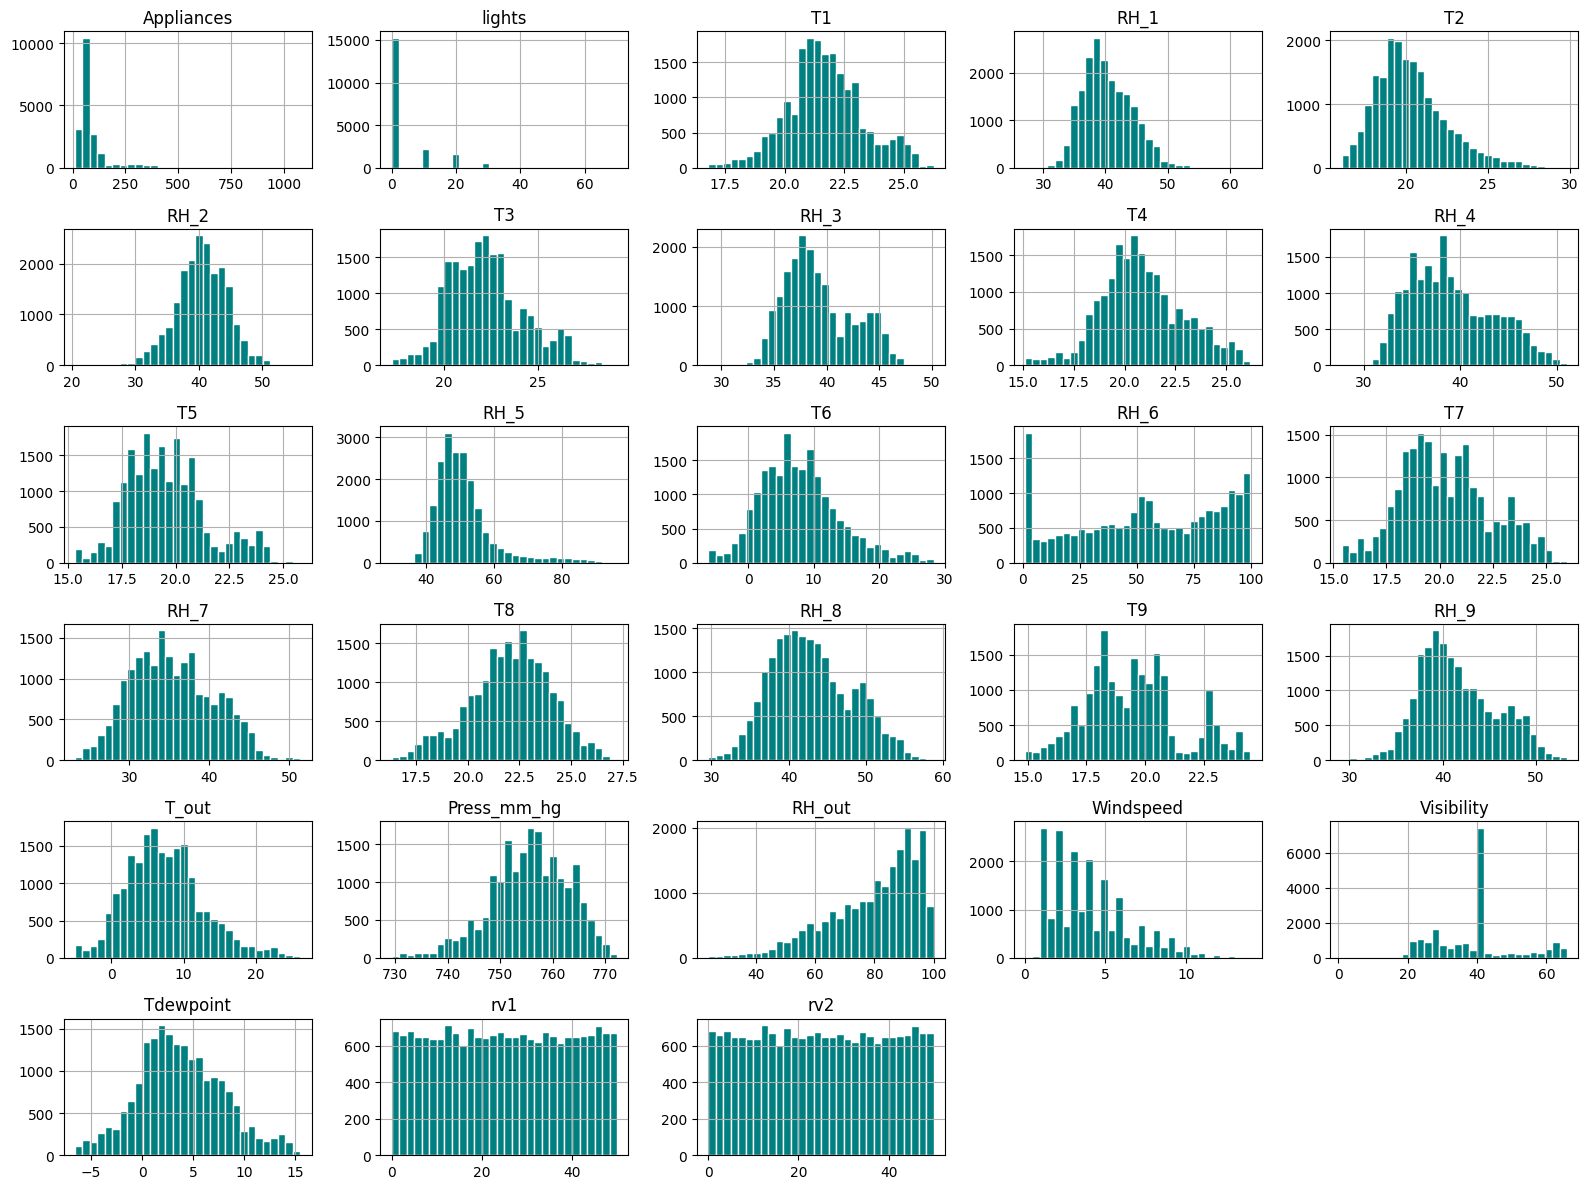

In [26]:
df.hist(figsize=(16, 12), bins=30, layout=(6, 5), color="teal", edgecolor="white")
plt.tight_layout()
plt.savefig("../reports/feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

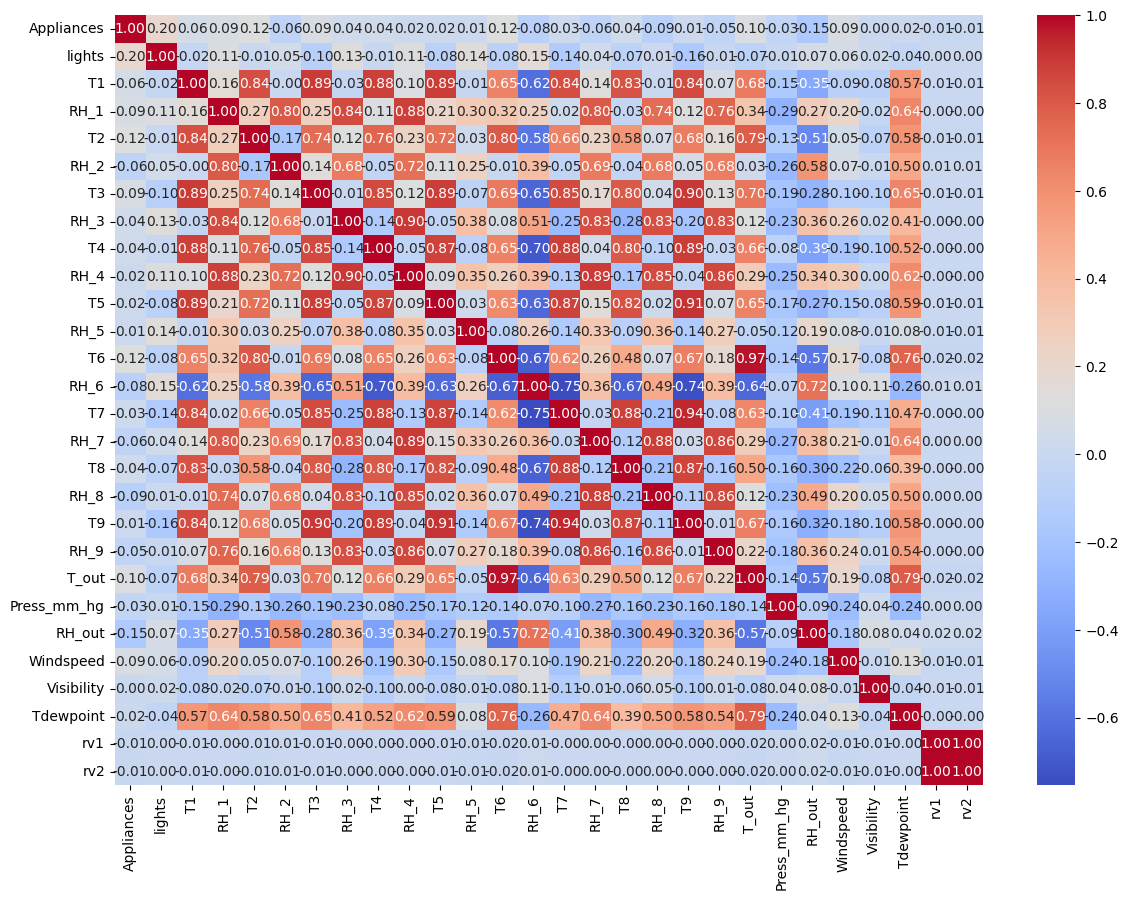

In [15]:
import seaborn as sns

corr_matrix = df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 10})
plt.show()

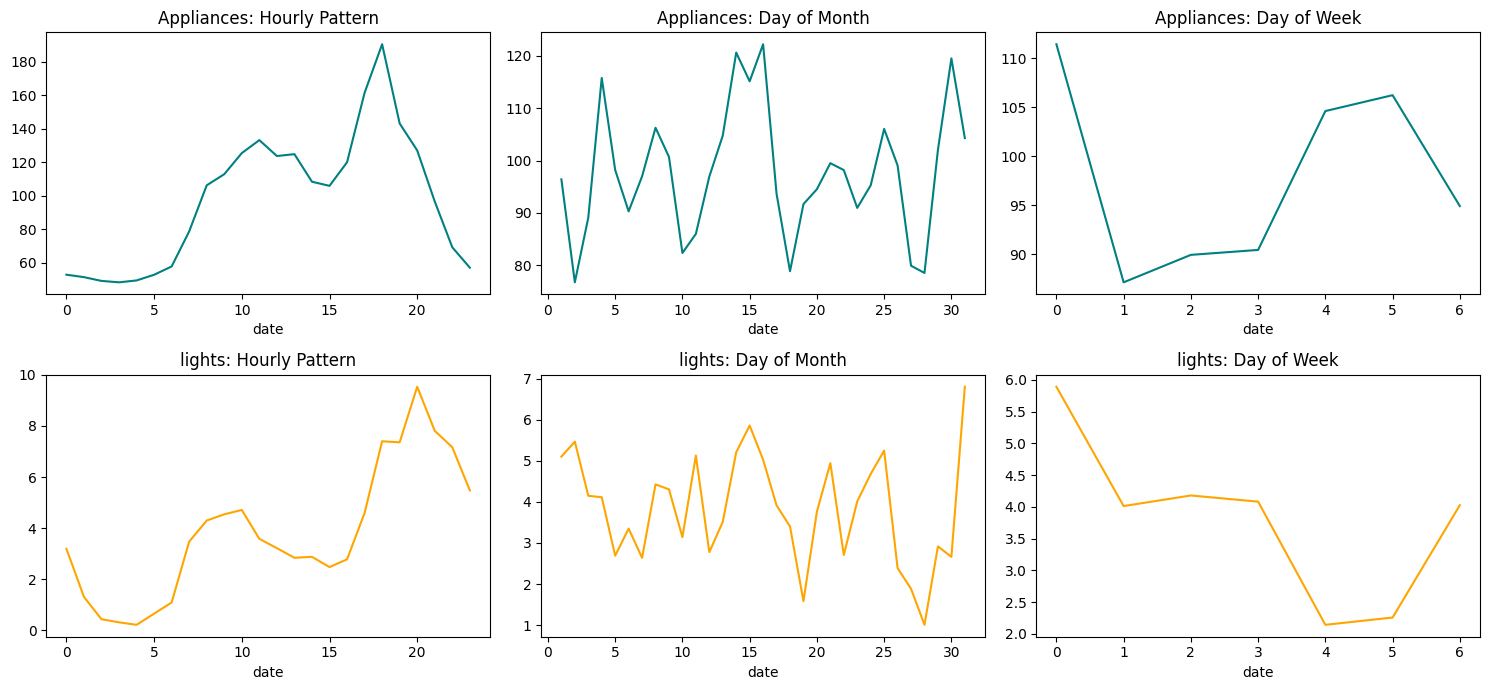

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for i, column in enumerate(["Appliances", "lights"]):
    color = "teal" if column == "Appliances" else "orange"
    df.groupby(df.index.hour)[column].mean().plot(ax=axes[i, 0], color=color, title=f"{column}: Hourly Pattern")
    df.groupby(df.index.day)[column].mean().plot(ax=axes[i, 1], color=color, title=f"{column}: Day of Month")
    df.groupby(df.index.dayofweek)[column].mean().plot(ax=axes[i, 2], color=color, title=f"{column}: Day of Week")

plt.tight_layout()
plt.show()

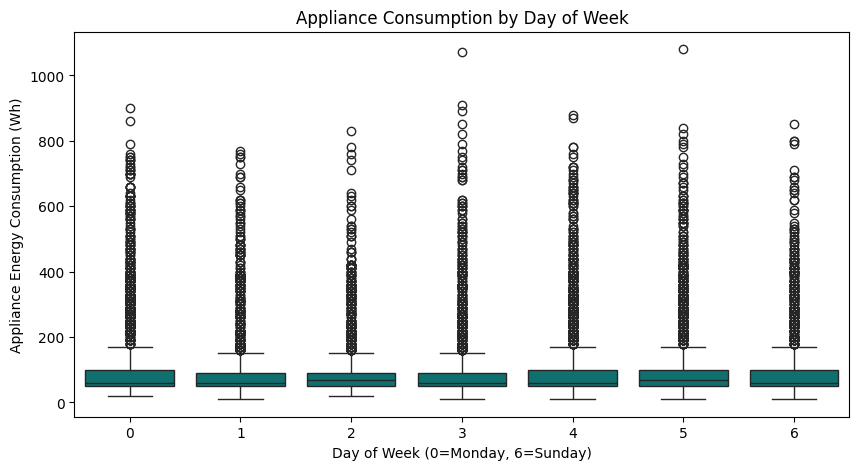

In [18]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df.index.dayofweek, y=df["Appliances"], color="teal")
plt.xlabel("Day of Week (0=Monday, 6=Sunday)")
plt.ylabel("Appliance Energy Consumption (Wh)")
plt.title("Appliance Consumption by Day of Week")
plt.show()

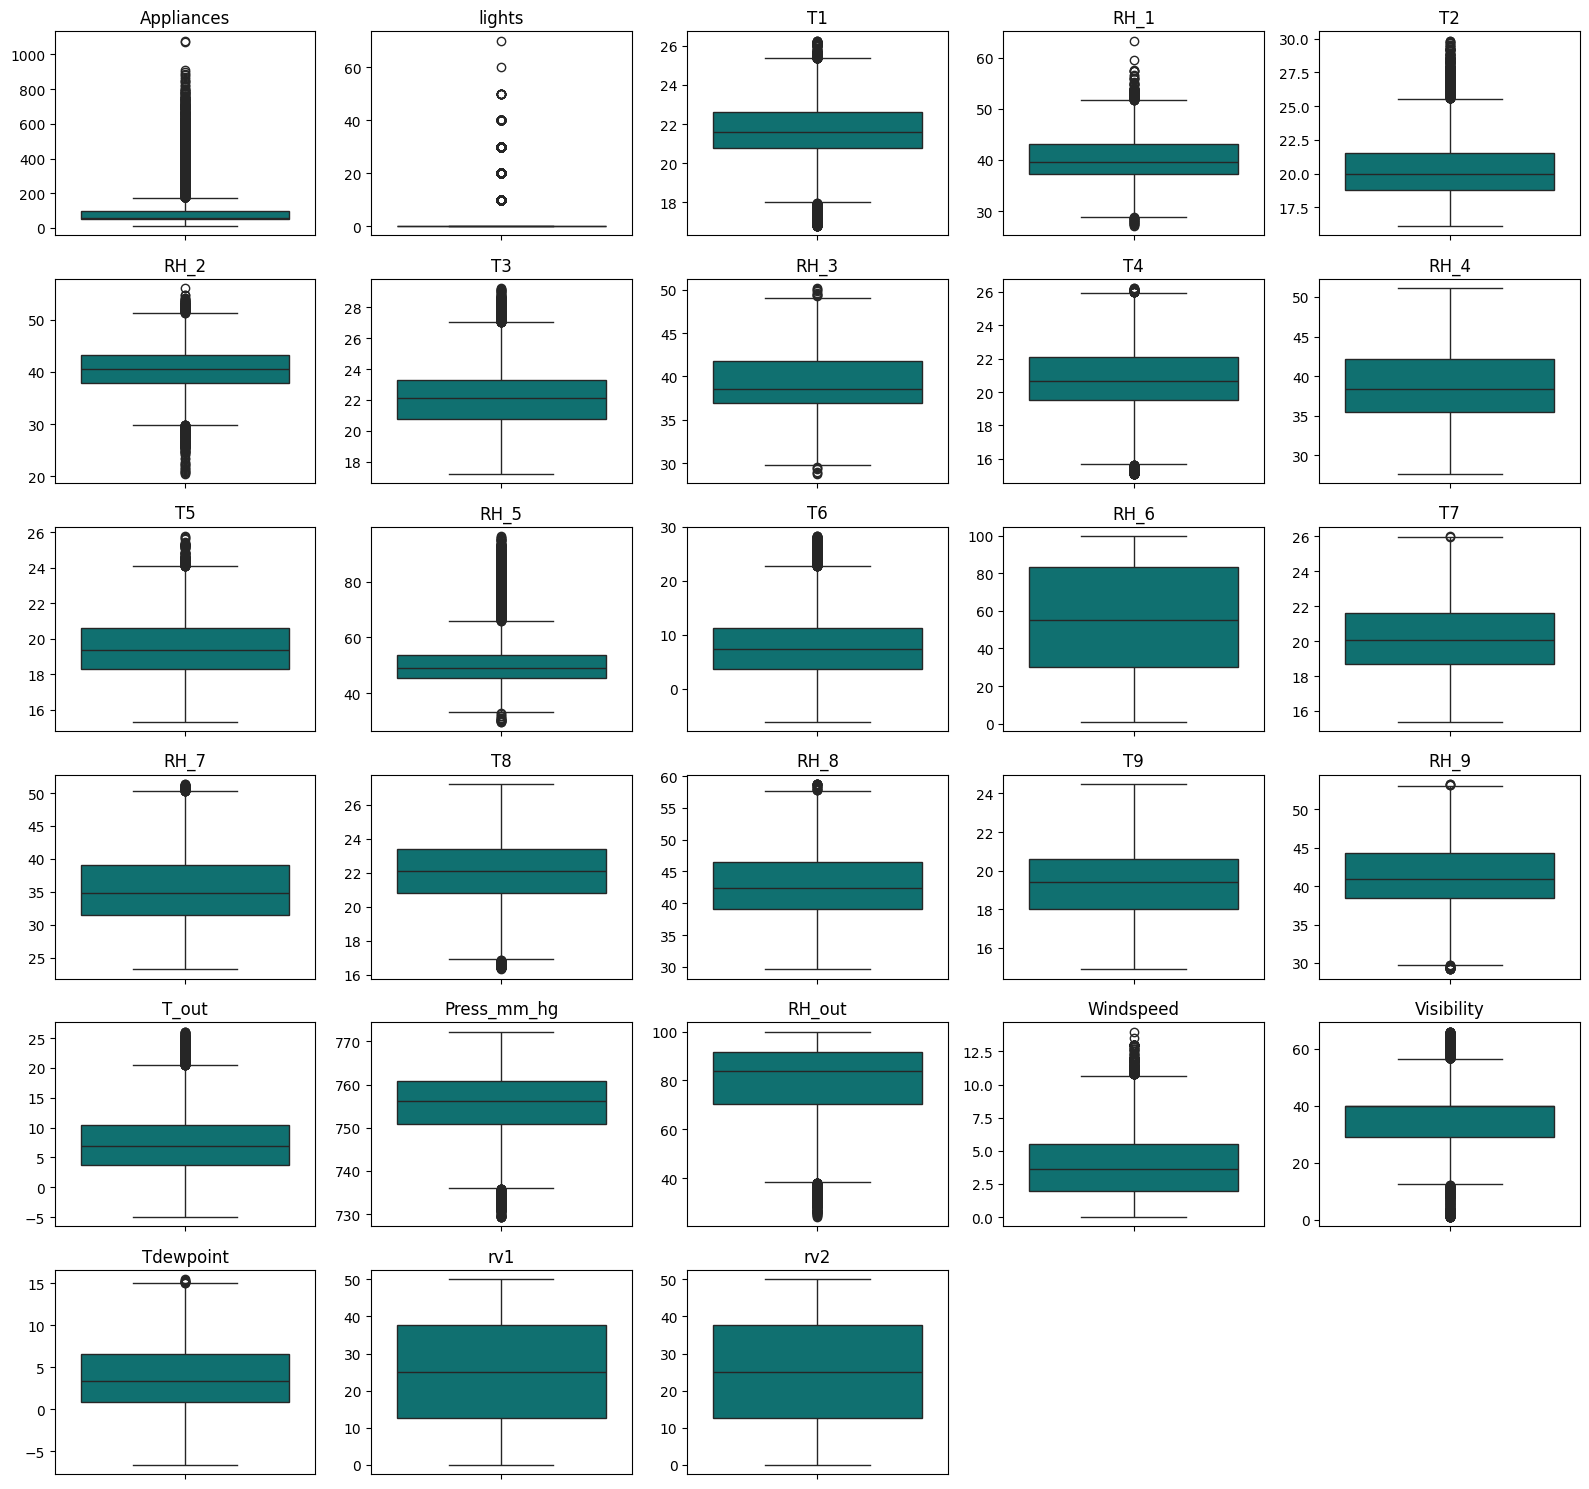

In [29]:
fig, axes = plt.subplots(6, 5, figsize=(16, 15))

for ax, column in zip(axes.flat, df.columns):
    sns.boxplot(y=df[column], ax=ax, color="teal")
    ax.set_title(column)
    ax.set_ylabel("")

for ax in axes.flat[len(df.columns):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
df.groupby(df.index.dayofweek)["Appliances"].agg(["mean", "median", "std", "max"]).round(2)

,mean,median,std,max
date,,,,
0,111.45,60.0,122.12,900
1,87.12,60.0,90.98,770
2,89.93,70.0,80.73,830
3,90.43,60.0,98.31,1070
4,104.62,60.0,116.25,880
5,106.25,70.0,110.22,1080
6,94.92,60.0,90.51,850


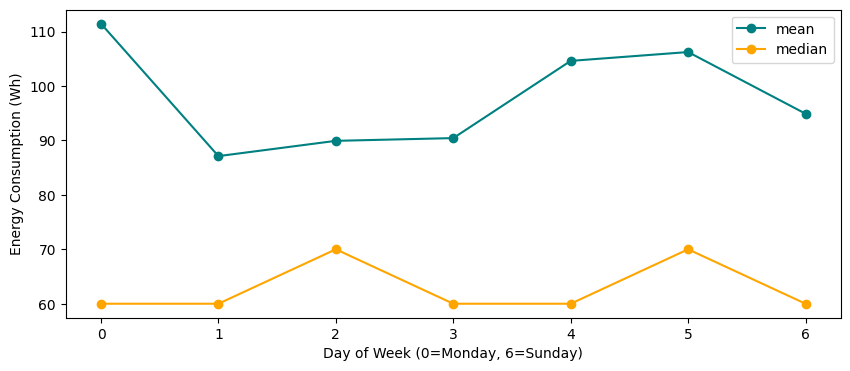

In [20]:
weekly = df.groupby(df.index.dayofweek)["Appliances"].agg(["mean", "median"])

weekly.plot(figsize=(10, 4), color=["teal", "orange"], marker="o")
plt.xlabel("Day of Week (0=Monday, 6=Sunday)")
plt.ylabel("Energy Consumption (Wh)")
plt.show()

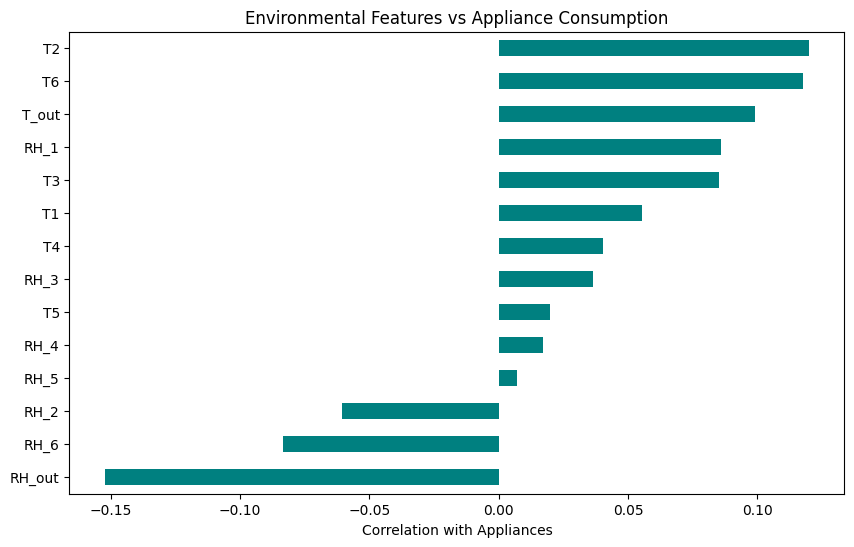

In [21]:
columns = ["Appliances", "T1", "T2", "T3", "T4", "T5", "T6", "RH_1", "RH_2", "RH_3", "RH_4", "RH_5", "RH_6", "T_out", "RH_out"]

corr = df[columns].corr()["Appliances"].drop("Appliances").sort_values()

corr.plot(kind="barh", figsize=(10, 6), color="teal")
plt.xlabel("Correlation with Appliances")
plt.title("Environmental Features vs Appliance Consumption")
plt.show()

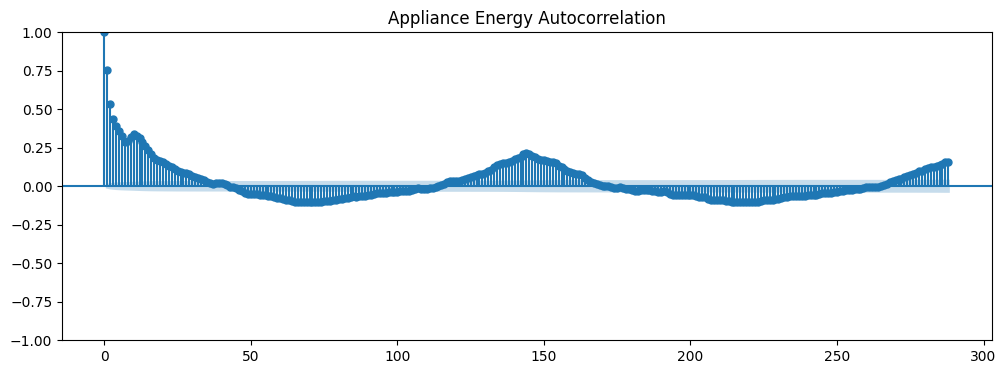

In [22]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df["Appliances"].dropna(), lags=288, ax=ax)
plt.title("Appliance Energy Autocorrelation")
plt.show()

In [23]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Appliances"] < lower_bound) | (df["Appliances"] > upper_bound)]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Lower Bound: -25.0
Upper Bound: 175.0
Outlier Count: 2138
Outlier Percentage: 10.83 %


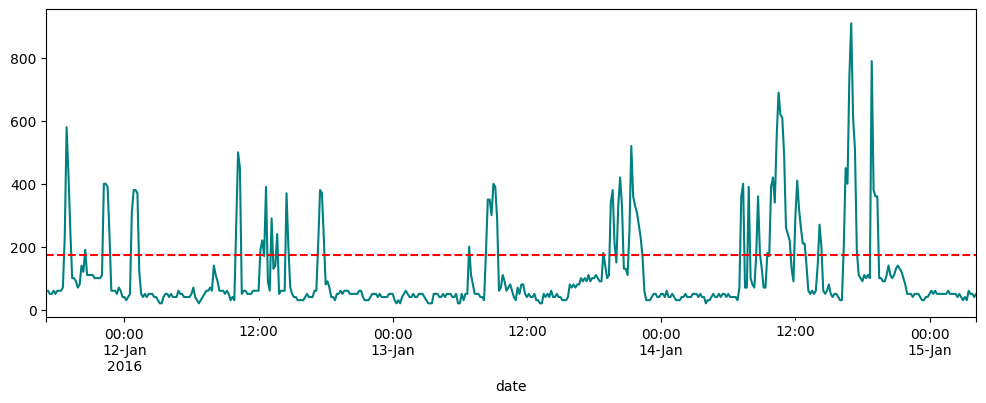

In [24]:
df["Appliances"].iloc[:500].plot(figsize=(12, 4), color="teal")
plt.axhline(upper_bound, color="red", linestyle="--")
plt.show()

In [25]:
from pathlib import Path
Path("data").mkdir(parents=True, exist_ok=True)
df.to_parquet("data/eda.parquet")